# Hydropathy reference for testing feature 8893

**Kyte–Doolittle hydropathy scale.** Higher values indicate more hydrophobic character; lower values indicate more hydrophilic character on this scale. Values are unnormalized.

Source: [ExPASy ProtScale — Kyte & Doolittle](https://web.expasy.org/protscale/pscale/Hphob.Doolittle.html), citing Kyte J. & Doolittle R.F., *J. Mol. Biol.* **157**, 105–132 (1982).

| Amino acid | One-letter code | Hydropathy |
|---|:---:|---:|
| Alanine | A | 1.8 |
| Arginine | R | -4.5 |
| Asparagine | N | -3.5 |
| Aspartic acid | D | -3.5 |
| Cysteine | C | 2.5 |
| Glutamine | Q | -3.5 |
| Glutamic acid | E | -3.5 |
| Glycine | G | -0.4 |
| Histidine | H | -3.2 |
| Isoleucine | I | 4.5 |
| Leucine | L | 3.8 |
| Lysine | K | -3.9 |
| Methionine | M | 1.9 |
| Phenylalanine | F | 2.8 |
| Proline | P | -1.6 |
| Serine | S | -0.8 |
| Threonine | T | -0.7 |
| Tryptophan | W | -0.9 |
| Tyrosine | Y | -1.3 |
| Valine | V | 4.2 |

In [10]:
# GPT 6.1 Sol High Effort implemented the function below to calculate hydropathy and aided my understanding of hydropathy

**Calculation:** centered sliding-window arithmetic mean, default **19 residues**, with equal weights and no normalization. [ProtScale documentation](https://web.expasy.org/protscale/protscale-doc.html) recommends 19 or 21 residues for highlighting hydrophobic membrane-spanning stretches. An odd window gives each mean an exact central residue; try smaller odd windows to inspect shorter stretches.

The function below returns one row per residue with **1-based positions**, the individual residue value (`hydropathy`), and the local mean (`window_mean`). Positions without a complete centered window are `NaN` (the first/last 9 residues for window 19). For a whole-sequence mean, use `profile['hydropathy'].mean()`; local scores retain the stretches that this average hides. 

Note that Hydropathy alone does not establish membrane topology.

**Formula used by the function:**

$$
H_w(i) = \frac{1}{w}\sum_{j=-k}^{k} h(a_{i+j}),
\qquad k = \frac{w-1}{2}.
$$

Here $a_i$ is the residue at 1-based position $i$, $h(a_i)$ is its Kyte–Doolittle lookup value, $w$ is the odd window size, and $H_w(i)$ is the returned `window_mean`. Each residue in the window has equal weight. For the default $w=19$, this averages residue $i$ and its 9 neighbours on each side. For a sequence of length $L$, the formula is evaluated only where $k+1 \leq i \leq L-k$; other positions are `NaN`.


In [6]:
import pandas as pd


# Unnormalized Kyte–Doolittle values, as listed by ExPASy ProtScale:
# https://web.expasy.org/protscale/pscale/Hphob.Doolittle.html
KYTE_DOOLITTLE = {
    'A': 1.8, 'R': -4.5, 'N': -3.5, 'D': -3.5, 'C': 2.5,
    'Q': -3.5, 'E': -3.5, 'G': -0.4, 'H': -3.2, 'I': 4.5,
    'L': 3.8, 'K': -3.9, 'M': 1.9, 'F': 2.8, 'P': -1.6,
    'S': -0.8, 'T': -0.7, 'W': -0.9, 'Y': -1.3, 'V': 4.2,
}


def calculate_hydropathy(sequence: str, window: int = 19) -> pd.DataFrame:
    """Return per-residue Kyte–Doolittle values and centered window means.

    Accepts a plain one-letter sequence; lowercase and whitespace are
    normalized. Rejects empty sequences and symbols outside the 20-residue
    scale (including unknown/ambiguous residues, gaps and stop markers).
    The window must be a positive odd integer no longer than the sequence.
    Positions are 1-based after whitespace removal. Incomplete windows at
    the termini are NaN; individual residue values remain available there.
    """
    if not isinstance(sequence, str):
        raise TypeError('sequence must be a plain one-letter amino acid string.')
    sequence = ''.join(sequence.split()).upper()
    if not sequence:
        raise ValueError('sequence must contain at least one amino acid.')
    unsupported = sorted(set(sequence) - KYTE_DOOLITTLE.keys())
    if unsupported:
        raise ValueError(f'No Kyte–Doolittle value for: {unsupported}')
    if isinstance(window, bool) or not isinstance(window, int):
        raise TypeError('window must be a positive odd integer.')
    if window < 1 or window % 2 == 0:
        raise ValueError('window must be a positive odd integer.')
    if window > len(sequence):
        raise ValueError('window exceeds sequence length; choose a smaller odd window.')

    profile = pd.DataFrame({
        'position': range(1, len(sequence) + 1),
        'residue': list(sequence),
        'hydropathy': [KYTE_DOOLITTLE[aa] for aa in sequence],
    })
    profile['window_mean'] = profile['hydropathy'].rolling(
        window=window, center=True, min_periods=window
    ).mean()
    return profile

In [7]:
# Synthetic illustration only: hydrophilic / hydrophobic / hydrophilic.
example_profile = calculate_hydropathy('E' * 19 + 'I' * 19 + 'E' * 19)
# Centers of the three stretches: expected means -3.5, 4.5, -3.5.
example_profile.iloc[[9, 28, 47]]

,position,residue,hydropathy,window_mean
9,10,E,-3.5,-3.5
28,29,I,4.5,4.5
47,48,E,-3.5,-3.5


## Hydropathy along the sequence

`plot_hydropathy(sequence)` draws a wrapped colour bar with one letter per residue and 1-based sequence positions. **Blue = more hydrophilic; orange = more hydrophobic; near-white = around zero.** All plots use the same −4.5 to +4.5 scale so colours are comparable across proteins.

Colours show the **19-residue sliding mean** by default; use `window=1` for individual residue values. Grey marks incomplete terminal windows. Set `residues_per_line` to control wrapping (default 60). The function returns the Matplotlib figure and sequence axes for saving or further annotation.


In [8]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch


def plot_hydropathy(
    sequence: str,
    window: int = 19,
    residues_per_line: int = 60,
    title: str | None = None,
):
    """Plot a wrapped residue strip coloured by Kyte–Doolittle hydropathy.

    Uses calculate_hydropathy for sequence validation and centered means.
    window=1 gives individual residue values. Incomplete windows are grey.
    Colours always span -4.5 to +4.5, with zero at the neutral midpoint.
    Returns (figure, list_of_sequence_axes); call figure.savefig(...) to export.
    """
    if isinstance(residues_per_line, bool) or not isinstance(residues_per_line, int):
        raise TypeError('residues_per_line must be a positive integer.')
    if residues_per_line < 1:
        raise ValueError('residues_per_line must be a positive integer.')
    profile = calculate_hydropathy(sequence, window=window)
    columns = min(residues_per_line, len(profile))
    rows = (len(profile) + columns - 1) // columns

    cmap = LinearSegmentedColormap.from_list(
        'kyte_doolittle', ['#2166ac', '#f7f7f7', '#b35806']
    )
    cmap.set_bad('#d9dde3')
    norm = Normalize(vmin=-4.5, vmax=4.5)
    mode = 'Individual residue values' if window == 1 else f'{window}-residue centered mean'
    fig = plt.figure(figsize=(max(8, columns * 0.21 + 1.6), rows * 0.8 + 1.9))
    grid = fig.add_gridspec(
        rows + 1, 1, height_ratios=[1] * rows + [0.3], hspace=1.15,
        left=0.06, right=0.94, top=1 - 0.75 / fig.get_figheight(),
        bottom=0.85 / fig.get_figheight(),
    )
    fig.suptitle(f'{title or "Sequence hydropathy"} — {mode}', y=0.98, fontsize=13)
    axes = []
    for row in range(rows):
        start = row * columns
        segment = profile.iloc[start:start + columns]
        values = segment['window_mean'].to_numpy()
        ax = fig.add_subplot(grid[row])
        strip = ax.imshow(
            np.ma.masked_invalid(values[np.newaxis, :]),
            cmap=cmap, norm=norm, interpolation='nearest', aspect='auto',
            extent=(0, len(segment), 0, 1),
        )
        for offset, (residue, value) in enumerate(zip(segment['residue'], values)):
            rgba = cmap(norm(value)) if np.isfinite(value) else cmap.get_bad()
            luminance = np.dot(rgba[:3], [0.2126, 0.7152, 0.0722])
            ax.text(
                offset + 0.5, 0.5, residue, ha='center', va='center',
                fontfamily='monospace', fontsize=10,
                color='white' if luminance < 0.48 else '#17212b',
            )
        # Keep cell widths fixed, including on a partially filled final row.
        ax.set_xlim(0, columns)
        ax.set_ylim(0, 1)
        ax.set_yticks([])
        ticks = [p for p in segment['position'] if p % 10 == 0]
        ax.set_xticks([p - start - 0.5 for p in ticks], labels=ticks)
        ax.tick_params(axis='x', length=0, labelsize=8, colors='#536170', pad=3)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.text(-0.6, 0.5, str(start + 1), ha='right', va='center', fontsize=9)
        ax.text(len(segment) + 0.6, 0.5, str(start + len(segment)),
                ha='left', va='center', fontsize=9)
        axes.append(ax)

    colourbar = fig.colorbar(strip, cax=fig.add_subplot(grid[-1]), orientation='horizontal')
    colourbar.set_ticks([-4.5, -3, -1.5, 0, 1.5, 3, 4.5])
    colourbar.set_label('Kyte–Doolittle hydropathy: hydrophilic (−) → hydrophobic (+)', fontsize=10)
    colourbar.outline.set_visible(False)
    if profile['window_mean'].isna().any():
        fig.legend(
            handles=[Patch(facecolor=cmap.get_bad(), label='Incomplete centered window')],
            loc='lower right', bbox_to_anchor=(0.94, 0), frameon=False, fontsize=9,
        )
    return fig, axes


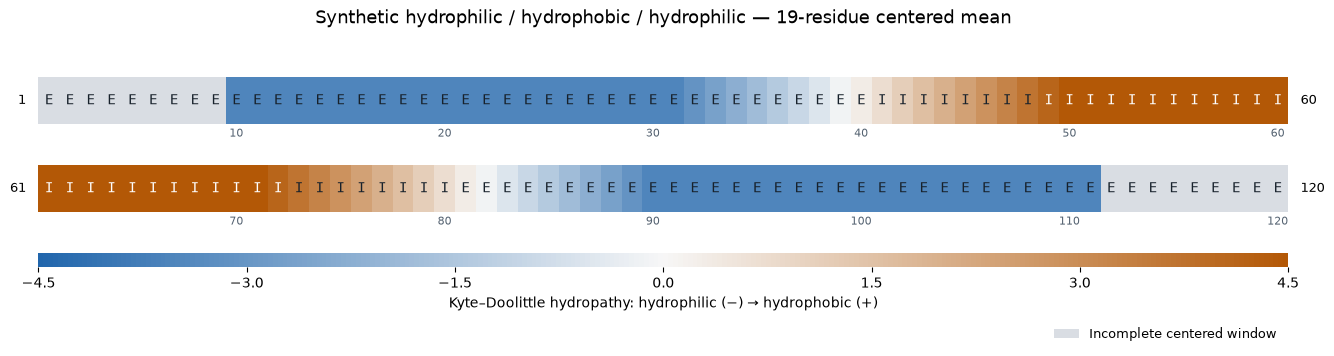

In [9]:
# Synthetic sequence only; illustrates the plotting function.
# The hydrophobic stretch crosses a line break to illustrate wrapping.
example_sequence = 'E' * 40 + 'I' * 40 + 'E' * 40
fig, axes = plot_hydropathy(example_sequence, title='Synthetic hydrophilic / hydrophobic / hydrophilic')
# For individual residues: plot_hydropathy(example_sequence, window=1)
# To export: fig.savefig('hydropathy.png', dpi=200, bbox_inches='tight')


In [11]:
# I used GPT 6.1 Sol High Effort to automate the fetching of these proteins to test the current hypothesis

## Protein panel: does feature 8893 follow hydrophobic stretches?

**Selected 22 November 2026: 15 reviewed proteins, 97–760 residues.** Five single-pass helical proteins, five multipass helical proteins, and five diagnostic controls (including a membrane β-barrel). Contexts span humans, bacteria, yeast, plants, a virus and an insect. Several repeat notebook 04 for continuity; this is an exploratory panel, not an independent validation set. No new feature-8893 activations were screened for selection.

**Scores:** calculated by executing this notebook's `calculate_hydropathy(sequence, window=19)` on the complete canonical UniProt sequences, including signal peptides. **Peak H19** is the largest centered 19-residue mean, rounded to 3 decimals; parentheses give its **19-residue window**, not a membrane annotation. All coordinates are **1-based, inclusive**; the earliest tied maximum is listed. The annotations and biological context come from the linked UniProt entries; scores and experimental rationales are our calculations/interpretations.

| Group | Protein / UniProt source | Biological context; reason to include | aa | Reference topology / processing | Peak H19 (window) |
|---|---|---|---:|---|---|
| Single-pass | **TFRC** — [P02786](https://www.uniprot.org/uniprotkb/P02786/entry) | Human iron uptake; large extracellular domain provides within-protein contrast. | 760 | 1 helix: 68–88 (type II) | **2.426** (66–84) |
| Single-pass | **CD8 alpha** — [P01732](https://www.uniprot.org/uniprotkb/P01732/entry) | Human T-cell co-receptor; compare a cleaved signal with the retained anchor. | 235 | Signal 1–21; 1 helix: 183–203 (type I) | **2.021** (1–19) |
| Single-pass | **FtsL** — [P0AEN4](https://www.uniprot.org/uniprotkb/P0AEN4/entry) | *E. coli* K-12 cell division; bacterial inner-membrane example. | 121 | 1 helix: 35–57 (type II) | **2.447** (38–56) |
| Single-pass | **M2** — [P06821](https://www.uniprot.org/uniprotkb/P06821/entry) | Influenza A/Puerto Rico/8/1934 (H1N1); viral proton channel. | 97 | 1 helix: 23–43 (type III) | **2.200** (25–43) |
| Single-pass | **Sso1** — [P32867](https://www.uniprot.org/uniprotkb/P32867/entry) | *S. cerevisiae* S288c vesicle fusion; very hydrophobic C-terminal anchor. | 290 | 1 helix: 266–287 (type IV) | **3.616** (269–287) |
| Multipass | **AQP1** — [P29972](https://www.uniprot.org/uniprotkb/P29972/entry) | Human water channel; full crossings and partial insertions in one sequence. | 269 | 6 helices; intramembrane 69–82, 187–199 | **2.184** (94–112) |
| Multipass | **LacY** — [P02920](https://www.uniprot.org/uniprotkb/P02920/entry) | *E. coli* K-12 lactose uptake; many separated membrane crossings. | 417 | 12 helices | **2.463** (76–94) |
| Multipass | **UCP1** — [P25874](https://www.uniprot.org/uniprotkb/P25874/entry) | Human brown-fat heat production; deliberately retains a modest-H19 membrane protein. | 307 | 6 helices; mitochondrial inner membrane | **1.684** (12–30) |
| Multipass | **D1 / PsbA** — [P83755](https://www.uniprot.org/uniprotkb/P83755/entry) | *Arabidopsis thaliana* photosynthesis; plant thylakoid membrane. | 353 | 5 helices | **2.337** (35–53) |
| Multipass | **Sec61** — [P32915](https://www.uniprot.org/uniprotkb/P32915/entry) | *S. cerevisiae* S288c protein import; ER translocation channel. | 480 | 10 helices | **2.826** (149–167) |
| Control | **Caveolin-1** — [Q03135](https://www.uniprot.org/uniprotkb/Q03135/entry) | Human caveolae; hydrophobic membrane insertion without a full bilayer crossing. | 178 | Intramembrane 105–125; monotopic ([structure](https://www.rcsb.org/structure/7SC0)) | **2.079** (113–131) |
| Control | **Firefly luciferase** — [P08659](https://www.uniprot.org/uniprotkb/P08659/entry) | *Photinus pyralis* light production; soluble peroxisomal enzyme with a hydrophobic stretch. | 550 | No annotated TM, intramembrane or signal peptide | **1.974** (85–103) |
| Control | **Calmodulin-1** — [P0DP23](https://www.uniprot.org/uniprotkb/P0DP23/entry) | Human calcium signalling; low-H19 soluble comparison, reused from earlier analysis. | 149 | No annotated TM, intramembrane or signal peptide | **0.221** (56–74) |
| Control | **Lysozyme C** — [P00698](https://www.uniprot.org/uniprotkb/P00698/entry) | Chicken antibacterial enzyme; hydrophobic secretion signal versus mature soluble protein. | 147 | Signal 1–18; mature chain 19–147; no stable TM | **2.363** (4–22) |
| Control | **OmpF** — [P02931](https://www.uniprot.org/uniprotkb/P02931/entry) | *E. coli* K-12 outer-membrane pore; membrane location with a β-barrel architecture. | 362 | Signal 1–22; mature β-barrel 23–362 ([structure](https://www.rcsb.org/structure/2OMF)) | **1.795** (5–23) |

**Contrasts to inspect**

- **Hydrophobic without a full crossing:** luciferase's 85–103 stretch scores **1.974** despite no annotated membrane segment; caveolin-1 provides a membrane-embedded, one-leaflet (**monotopic**) comparison. Its 105–125 intramembrane annotation is not the entire membrane-contacting surface of the oligomer ([cryo-EM structure](https://www.rcsb.org/structure/7SC0)).
- **Signal versus retained membrane anchor:** CD8 alpha's highest window is its signal peptide; the maximum window wholly inside its retained 183–203 anchor is **1.947** (185–203). Lysozyme's peak overlaps its cleaved signal; the mature 19–147 chain has a maximum of **0.905** using only windows wholly inside that chain.
- **Membrane location versus long hydrophobic helices:** mature OmpF is a membrane β-barrel, but windows wholly within 23–362 peak at only **0.689**; its full-sequence maximum is signal-associated. Keep this distinct from a soluble negative control. UCP1 also tests a membrane protein with a modest H19 peak.
- **Partial insertions and low-H19 regions:** AQP1 has two re-entrant intramembrane sections as well as six full crossings. Those insertions are shorter than 19 residues, so their window scores include neighbours. Calmodulin supplies a low-H19 soluble baseline; hydrophilic loops/domains within the membrane proteins supply further comparisons.

Compare residue-level feature activation with **continuous H19**, including high- and low-scoring regions within each sequence. Peak scores describe why the panel is informative; they do not establish feature activation or classify membrane topology. Keep the full panel, including weak/zero responses.

<details>
<summary>Sources, frozen sequences and reproducing the scores</summary>

The [reference snapshot](data/reference/feature_8893_hydropathy_panel.json) preserves the selected sequences, entry/sequence versions, membrane/processing intervals with their evidence codes, unrounded score summaries, and the screened alternatives. Source JSON for each entry is `https://rest.uniprot.org/uniprotkb/ACCESSION.json`. Exact boundary evidence varies: many helical intervals are sequence-based predictions, while AQP1 includes structure-linked evidence; a reviewed entry does not make every boundary experimentally established. The snapshot retains OmpF's individual β-stranded feature intervals without treating them as α-helices.

To regenerate any profile using the same function defined above:

```python
import json
from pathlib import Path

panel = json.loads(Path('data/reference/feature_8893_hydropathy_panel.json').read_text())
protein = panel['proteins'][0]
profile = calculate_hydropathy(protein['sequence']['value'], window=19)
profile['window_mean'].max()
```

Scale/method: [ExPASy Kyte–Doolittle values](https://web.expasy.org/protscale/pscale/Hphob.Doolittle.html), [ProtScale sliding-window documentation](https://web.expasy.org/protscale/protscale-doc.html). Sequences and extracted annotations: UniProt Consortium, [CC BY 4.0](https://www.uniprot.org/help/license); field extraction and hydropathy summaries are modifications.

</details>
